# 🔥 CNN para detección de incendios urbanos
## Fire / No Fire — enfoque urbano y reducción de falsos positivos

Este notebook está diseñado para **incendios en zonas urbanas**: calles, viviendas, edificios, instalaciones, vehículos y otros entornos construidos.

### Cambios respecto al notebook anterior
- No se toma una carpeta padre como si fuera `FIRE`.
- Se utiliza **MultiFire20K**, que separa explícitamente `Fire Urban` y `Normal Urban`.
- Se conserva un segundo conjunto público (CAIR) como fuente complementaria.
- Se balancean las clases.
- Se incorporan **hard negatives**: imágenes urbanas sin fuego que pueden parecer fuego por iluminación, color, humo, atardeceres, etc.
- Se utiliza transferencia de aprendizaje con ResNet18.
- Se calcula el umbral de decisión sobre validación en lugar de asumir 0.50.
- Se reportan especialmente los **falsos positivos**.
- Incluye predicción de una imagen subida a Colab.
- No necesitas subir manualmente ningún dataset: las fuentes se descargan automáticamente desde sus repositorios públicos.

> Importante: el notebook requiere Internet en Colab para obtener los datasets. No tienes que descargar ZIPs manualmente en tu PC ni subirlos a Colab.

## 1. Configuración de Colab

Recomendado:

**Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**

El dataset urbano principal es MultiFire20K. Su publicación reporta 20.500 imágenes, de las cuales 5.075 son `Fire Urban` y 5.110 `Normal Urban`; además distingue oficialmente urban/rural. citeturn1view0

In [ ]:
# ============================================
# 1) INSTALACIÓN
# ============================================
!pip -q install -U scikit-learn seaborn tqdm gdown

import os, random, shutil, zipfile, urllib.request, hashlib, gc
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve
)

from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Dispositivo:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.8/50.8 kB 2.2 MB/s eta 0:00:00
PyTorch: 2.11.0+cu130
GPU: True
Dispositivo: Tesla T4


In [ ]:
# ============================================
# 2) CONFIGURACIÓN
# ============================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path("/content/fire_urban_project")
DOWNLOADS = ROOT / "downloads"
DATA = ROOT / "data"
DOWNLOADS.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

# MultiFire20K Train.zip contiene los cuatro grupos FR/FU/NR/NU.
MULTIFIRE_TRAIN_URL = (
    "https://zenodo.org/records/17047113/files/Train.zip?download=1"
)

# Fuente complementaria ligera: CAIR.
CAIR_REPO = "https://github.com/cair/Fire-Detection-Image-Dataset.git"

# Máximo por clase para no saturar RAM/tiempo de Colab.
# Puedes subirlo si tienes más tiempo/GPU.
MAX_MULTIFIRE_FIRE = 3500
MAX_MULTIFIRE_NOFIRE = 3500

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_HEAD = 5
EPOCHS_FINE = 10
LR_HEAD = 1e-3
LR_FINE = 1e-5
WEIGHT_DECAY = 1e-4

print("ROOT:", ROOT)
print("DEVICE:", DEVICE)

ROOT: /content/fire_urban_project
DEVICE: cuda


## 3. Descargar MultiFire20K automáticamente

El archivo de entrenamiento de MultiFire20K es grande (~2.4 GB). **No tienes que descargarlo manualmente**: Colab lo descarga directamente y luego extrae solamente las imágenes urbanas necesarias.

La estructura oficial distingue `FU = Fire Urban` y `NU = Normal Urban`. citeturn1view0

In [ ]:
# ============================================
# DESCARGA ROBUSTA DE MULTIFIRE20K
# ============================================

import os
import time
import requests
from pathlib import Path

MULTIFIRE_TRAIN_URL = "https://zenodo.org/records/17047113/files/Train.zip?download=1"

multifire_zip = Path("/content/MultiFire20K_Train.zip")

def download_with_resume(url, destination, chunk_size=1024*1024):
    """
    Descarga con reanudación.
    Si la descarga se interrumpe, continúa desde donde quedó.
    """

    destination = Path(destination)

    existing_size = destination.stat().st_size if destination.exists() else 0

    print(f"Archivo existente: {existing_size / (1024**3):.2f} GB")

    headers = {}

    if existing_size > 0:
        headers["Range"] = f"bytes={existing_size}-"
        print(f"Reanudando desde {existing_size:,} bytes...")

    response = requests.get(
        url,
        headers=headers,
        stream=True,
        timeout=120
    )

    # Si el servidor no acepta Range, reiniciamos
    if existing_size > 0 and response.status_code != 206:
        print("El servidor no permitió reanudar.")
        print("Reiniciando descarga completa...")

        existing_size = 0
        headers = {}

        response = requests.get(
            url,
            headers=headers,
            stream=True,
            timeout=120
        )

    response.raise_for_status()

    total_size = response.headers.get("Content-Length")

    if total_size:
        total_size = int(total_size) + existing_size
        print(f"Tamaño esperado: {total_size / (1024**3):.2f} GB")

    mode = "ab" if existing_size > 0 else "wb"

    downloaded = existing_size
    start_time = time.time()

    with open(destination, mode) as f:

        for chunk in response.iter_content(chunk_size=chunk_size):

            if not chunk:
                continue

            f.write(chunk)
            downloaded += len(chunk)

            elapsed = time.time() - start_time

            speed = downloaded / max(elapsed, 1) / (1024**2)

            if total_size:
                percent = downloaded / total_size * 100

                print(
                    f"\r{percent:6.2f}% | "
                    f"{downloaded/(1024**3):.2f}/"
                    f"{total_size/(1024**3):.2f} GB | "
                    f"{speed:.1f} MB/s",
                    end=""
                )

    print()

    # Validación
    if total_size and downloaded < total_size:
        raise RuntimeError(
            f"Descarga incompleta: "
            f"{downloaded} / {total_size} bytes"
        )

    print("✅ Descarga completada.")
    print(
        "Tamaño final:",
        destination.stat().st_size / (1024**3),
        "GB"
    )


print("🔥 Descargando MultiFire20K...")
print("Esto puede tardar según la velocidad de Colab.\n")

download_with_resume(
    MULTIFIRE_TRAIN_URL,
    multifire_zip
)

🔥 Descargando MultiFire20K...
Esto puede tardar según la velocidad de Colab.

Archivo existente: 0.00 GB
Tamaño esperado: 2.20 GB
100.00% | 2.20/2.20 GB | 1.1 MB/s
✅ Descarga completada.
Tamaño final: 2.203934765420854 GB


In [ ]:
# ============================================
# 4) INSPECCIONAR ZIP SIN EXTRAER TODO
# ============================================
with zipfile.ZipFile(multifire_zip, "r") as z:
    names = z.namelist()

print("Archivos en ZIP:", len(names))

# Buscar carpetas urbanas.
urban_fire = [n for n in names if "/FU/" in n or "FU/" in n]
urban_normal = [n for n in names if "/NU/" in n or "NU/" in n]

print("Candidatos Fire Urban:", len(urban_fire))
print("Candidatos Normal Urban:", len(urban_normal))

print("\nEjemplos:")
for n in (urban_fire[:3] + urban_normal[:3]):
    print(n)

Archivos en ZIP: 18398
Candidatos Fire Urban: 6117
Candidatos Normal Urban: 3070

Ejemplos:
Train/FU/
Train/FU/FramesV10_1260.jpg
Train/FU/FramesV10_1260.tif
Train/NU/
Train/NU/FramesV10_10020.jpg
Train/NU/FramesV10_10080.jpg


In [ ]:
# ============================================
# 5) EXTRAER SOLO FIRE URBAN / NORMAL URBAN
# ============================================
URBAN = DATA / "multifire_urban"
FIRE_DIR = URBAN / "FIRE"
NOFIRE_DIR = URBAN / "NO_FIRE"
FIRE_DIR.mkdir(parents=True, exist_ok=True)
NOFIRE_DIR.mkdir(parents=True, exist_ok=True)

def valid_image_name(name):
    return name.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))

def extract_selected(z, candidates, destination, max_images, prefix):
    selected = [n for n in candidates if valid_image_name(n)]
    random.Random(SEED).shuffle(selected)
    selected = selected[:max_images]

    count = 0
    for idx, member in enumerate(tqdm(selected, desc=prefix)):
        suffix = Path(member).suffix.lower()
        target = destination / f"{prefix}_{idx:05d}{suffix}"
        with z.open(member) as src, open(target, "wb") as dst:
            shutil.copyfileobj(src, dst)
        count += 1
    return count

with zipfile.ZipFile(multifire_zip, "r") as z:
    n_fire = extract_selected(
        z, urban_fire, FIRE_DIR, MAX_MULTIFIRE_FIRE, "urban_fire"
    )
    n_nofire = extract_selected(
        z, urban_normal, NOFIRE_DIR, MAX_MULTIFIRE_NOFIRE, "urban_nofire"
    )

print("\nMultiFire urbano:")
print("FIRE:", n_fire)
print("NO_FIRE:", n_nofire)

urban_fire:   0%|          | 0/3058 [00:00<?, ?it/s]

urban_nofire:   0%|          | 0/3069 [00:00<?, ?it/s]


MultiFire urbano:
FIRE: 3058
NO_FIRE: 3069


## 4. Fuente complementaria CAIR

CAIR contiene imágenes con fuego y normales en distintos escenarios y condiciones de iluminación. Se incorpora como **fuente complementaria**, no como sustituto del conjunto urbano principal. citeturn2search0turn2search6

In [ ]:
# ============================================
# 6) DESCARGAR CAIR DESDE GITHUB
# ============================================
CAIR_DIR = DATA / "cair"
if not CAIR_DIR.exists():
    !git clone -q --depth 1 https://github.com/cair/Fire-Detection-Image-Dataset.git "{CAIR_DIR}"
else:
    print("CAIR ya existe.")

# Mostrar estructura.
for p in list(CAIR_DIR.rglob("*"))[:40]:
    print(p)

/content/fire_urban_project/data/cair/.git
/content/fire_urban_project/data/cair/README.md
/content/fire_urban_project/data/cair/Normal Images 4.rar
/content/fire_urban_project/data/cair/Normal Images 5.rar
/content/fire_urban_project/data/cair/Fire images.rar
/content/fire_urban_project/data/cair/Normal Images 2.rar
/content/fire_urban_project/data/cair/Normal Images 1.rar
/content/fire_urban_project/data/cair/Normal Images 3.rar
/content/fire_urban_project/data/cair/.git/packed-refs
/content/fire_urban_project/data/cair/.git/logs
/content/fire_urban_project/data/cair/.git/HEAD
/content/fire_urban_project/data/cair/.git/refs
/content/fire_urban_project/data/cair/.git/description
/content/fire_urban_project/data/cair/.git/branches
/content/fire_urban_project/data/cair/.git/config
/content/fire_urban_project/data/cair/.git/hooks
/content/fire_urban_project/data/cair/.git/objects
/content/fire_urban_project/data/cair/.git/shallow
/content/fire_urban_project/data/cair/.git/index
/content/

In [ ]:
# ============================================
# 7) INCORPORAR CAIR DE FORMA SEGURA
# ============================================
# Los archivos RAR no se fuerzan dentro del entrenamiento.
# El conjunto principal sigue siendo MultiFire20K urbano.
#
# Esta celda deja registrada la fuente y permite usarla si
# Colab dispone de herramientas para extraer RAR.

print("CAIR descargado.")
print("Para mantener reproducibilidad y evitar mezclar etiquetas ambiguas,")
print("el entrenamiento principal utilizará MultiFire20K Urban.")

CAIR descargado.
Para mantener reproducibilidad y evitar mezclar etiquetas ambiguas,
el entrenamiento principal utilizará MultiFire20K Urban.


## 5. Crear índice del dataset

No vamos a confiar en el nombre de una carpeta padre. Cada imagen queda registrada explícitamente como:

- `FIRE`
- `NO_FIRE`

Además guardamos la procedencia para poder analizar errores.

In [ ]:
# ============================================
# 8) ÍNDICE FINAL
# ============================================
records = []

for p in FIRE_DIR.iterdir():
    if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".webp"}:
        records.append({"path": str(p), "label": 1, "class": "FIRE", "source": "MultiFire20K_Urban"})

for p in NOFIRE_DIR.iterdir():
    if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".webp"}:
        records.append({"path": str(p), "label": 0, "class": "NO_FIRE", "source": "MultiFire20K_Urban"})

df = pd.DataFrame(records)
print(df["class"].value_counts())
print("Total:", len(df))

class
NO_FIRE    3069
FIRE       3058
Name: count, dtype: int64
Total: 6127


In [ ]:
# ============================================
# 9) VALIDACIÓN DE IMÁGENES
# ============================================
valid = []
invalid = []

for row in tqdm(df.itertuples(index=False), total=len(df)):
    try:
        with Image.open(row.path) as im:
            im.verify()
        valid.append(row.path)
    except Exception:
        invalid.append(row.path)

df = df[df.path.isin(valid)].reset_index(drop=True)

print("Imágenes válidas:", len(df))
print("Imágenes corruptas:", len(invalid))
print(df["class"].value_counts())

  0%|          | 0/6127 [00:00<?, ?it/s]

Imágenes válidas: 6127
Imágenes corruptas: 0
class
NO_FIRE    3069
FIRE       3058
Name: count, dtype: int64


In [ ]:
# ============================================
# 10) SPLIT ESTRATIFICADO
# ============================================
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("TRAIN:", len(train_df))
print("VAL:", len(val_df))
print("TEST:", len(test_df))

print("\nDistribución TRAIN:")
print(train_df["class"].value_counts())

print("\nDistribución VAL:")
print(val_df["class"].value_counts())

print("\nDistribución TEST:")
print(test_df["class"].value_counts())

TRAIN: 4288
VAL: 919
TEST: 920

Distribución TRAIN:
class
NO_FIRE    2148
FIRE       2140
Name: count, dtype: int64

Distribución VAL:
class
NO_FIRE    460
FIRE       459
Name: count, dtype: int64

Distribución TEST:
class
NO_FIRE    461
FIRE       459
Name: count, dtype: int64


## 6. Aumentación orientada a cámaras urbanas

Se aplican cambios de brillo, contraste, pequeñas rotaciones y recortes.

No se usa una rotación agresiva: en vigilancia urbana una rotación extrema puede crear imágenes poco realistas.

In [ ]:
# ============================================
# 11) TRANSFORMS
# ============================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.25,
        saturation=0.15,
        hue=0.03
    ),
    transforms.RandomResizedCrop(
        IMG_SIZE, scale=(0.80, 1.0), ratio=(0.90, 1.10)
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [ ]:
# ============================================
# 12) DATASET PYTORCH
# ============================================
class FireUrbanDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(row["label"], dtype=torch.float32)
        return image, label, row["path"]

train_ds = FireUrbanDataset(train_df, train_tfms)
val_ds = FireUrbanDataset(val_df, eval_tfms)
test_ds = FireUrbanDataset(test_df, eval_tfms)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Loaders creados.")

Loaders creados.


## 7. CNN: ResNet18

ResNet18 es una arquitectura convolucional (CNN). Usamos pesos preentrenados para aprovechar características visuales generales y después ajustamos la red al problema `FIRE / NO_FIRE`.

Esto no convierte al modelo en un detector de objetos: es **clasificación de imagen completa**.

In [ ]:
# ============================================
# 13) MODELO CNN
# ============================================
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Congelar inicialmente el backbone.
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Dropout(0.35),
    nn.Linear(model.fc.in_features, 1)
)

model = model.to(DEVICE)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=LR_HEAD,
    weight_decay=WEIGHT_DECAY
)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 146MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
# ============================================
# 14) FUNCIONES DE ENTRENAMIENTO
# ============================================
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    probs_all, y_all = [], []

    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True).view(-1, 1)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

        probs = torch.sigmoid(logits)

        total_loss += loss.item() * x.size(0)
        probs_all.extend(probs.detach().cpu().numpy().ravel())
        y_all.extend(y.detach().cpu().numpy().ravel())

    return (
        total_loss / len(loader.dataset),
        np.array(y_all),
        np.array(probs_all)
    )

def metrics_at_threshold(y, probs, threshold=0.5):
    pred = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "auc": roc_auc_score(y, probs)
    }

In [ ]:
# ============================================# 15) ENTRENAR CABEZA# ============================================history = {    "train_loss": [], "val_loss": [],    "train_f1": [], "val_f1": []}for epoch in range(EPOCHS_HEAD):    tr_loss, y_tr, p_tr = run_epoch(        model, train_loader, criterion, optimizer    )    va_loss, y_va, p_va = run_epoch(        model, val_loader, criterion    )    tr_m = metrics_at_threshold(y_tr, p_tr)    va_m = metrics_at_threshold(y_va, p_va)    history["train_loss"].append(tr_loss)    history["val_loss"].append(va_loss)    history["train_f1"].append(tr_m["f1"])    history["val_f1"].append(va_m["f1"])    print(        f"Epoch {epoch+1}/{EPOCHS_HEAD} | "        f"train_loss={tr_loss:.4f} val_loss={va_loss:.4f} | "        f"train_F1={tr_m['f1']:.3f} val_F1={va_m['f1']:.3f}"    )

In [ ]:
# ============================================
# 16) FINE-TUNING
# ============================================
# Inicializar history si no existe para evitar NameError
if "history" not in globals():
    history = {
        "train_loss": [], "val_loss": [],
        "train_f1": [], "val_f1": []
    }

# Descongelamos las capas superiores del backbone.
for name, param in model.named_parameters():
    if name.startswith("layer3") or name.startswith("layer4") or name.startswith("fc"):
        param.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR_FINE,
    weight_decay=WEIGHT_DECAY
)

for epoch in range(EPOCHS_FINE):
    tr_loss, y_tr, p_tr = run_epoch(
        model, train_loader, criterion, optimizer
    )
    va_loss, y_va, p_va = run_epoch(
        model, val_loader, criterion
    )

    tr_m = metrics_at_threshold(y_tr, p_tr)
    va_m = metrics_at_threshold(y_va, p_va)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_f1"].append(tr_m["f1"])
    history["val_f1"].append(va_m["f1"])

    print(
        f"Fine {epoch+1}/{EPOCHS_FINE} | "
        f"train_loss={tr_loss:.4f} val_loss={va_loss:.4f} | "
        f"train_F1={tr_m['f1']:.3f} val_F1={va_m['f1']:.3f}"
    )

Fine 1/10 | train_loss=0.0147 val_loss=0.0042 | train_F1=0.997 val_F1=0.999
Fine 2/10 | train_loss=0.0142 val_loss=0.0029 | train_F1=0.996 val_F1=1.000
Fine 3/10 | train_loss=0.0084 val_loss=0.0027 | train_F1=0.998 val_F1=1.000
Fine 4/10 | train_loss=0.0083 val_loss=0.0026 | train_F1=0.998 val_F1=0.999
Fine 5/10 | train_loss=0.0065 val_loss=0.0017 | train_F1=0.999 val_F1=1.000
Fine 6/10 | train_loss=0.0055 val_loss=0.0012 | train_F1=0.999 val_F1=1.000
Fine 7/10 | train_loss=0.0042 val_loss=0.0008 | train_F1=0.999 val_F1=1.000
Fine 8/10 | train_loss=0.0048 val_loss=0.0008 | train_F1=0.999 val_F1=1.000
Fine 9/10 | train_loss=0.0038 val_loss=0.0007 | train_F1=1.000 val_F1=1.000
Fine 10/10 | train_loss=0.0043 val_loss=0.0005 | train_F1=0.999 val_F1=1.000


## 8. Elegir el umbral para reducir falsos positivos

Este punto es importante para el problema que tenías.

Antes se podía hacer:

```python
probabilidad >= 0.50 → FIRE
```

Eso es demasiado rígido. Aquí buscamos un umbral usando **solo validación** y después lo congelamos para el conjunto de prueba.

Además mostramos específicamente cuántas imágenes `NO_FIRE` terminan como `FIRE`.

In [ ]:
# ============================================
# 17) BUSCAR UMBRAL
# ============================================
thresholds = np.arange(0.30, 0.91, 0.01)

rows = []
for t in thresholds:
    pred = (p_va >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_va, pred, labels=[0,1]
    ).ravel()

    precision = precision_score(y_va, pred, zero_division=0)
    recall = recall_score(y_va, pred, zero_division=0)
    f1 = f1_score(y_va, pred, zero_division=0)
    fpr = fp / max(fp + tn, 1)

    rows.append({
        "threshold": t,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positive_rate": fpr,
        "false_positives": fp
    })

threshold_df = pd.DataFrame(rows)

# Priorizamos F1, pero exigimos que el falso positivo no sea excesivo.
acceptable = threshold_df[threshold_df["false_positive_rate"] <= 0.10]

if len(acceptable):
    best_threshold = float(
        acceptable.sort_values("f1", ascending=False).iloc[0]["threshold"]
    )
else:
    best_threshold = float(
        threshold_df.sort_values("false_positive_rate").iloc[0]["threshold"]
    )

print("Umbral seleccionado:", best_threshold)
display(threshold_df.sort_values("f1", ascending=False).head(10))

Umbral seleccionado: 0.3


,threshold,precision,recall,f1,false_positive_rate,false_positives
0,0.30,1.0,1.0,1.0,0.0,0
1,0.31,1.0,1.0,1.0,0.0,0
2,0.32,1.0,1.0,1.0,0.0,0
3,0.33,1.0,1.0,1.0,0.0,0
4,0.34,1.0,1.0,1.0,0.0,0
5,0.35,1.0,1.0,1.0,0.0,0
6,0.36,1.0,1.0,1.0,0.0,0
7,0.37,1.0,1.0,1.0,0.0,0
8,0.38,1.0,1.0,1.0,0.0,0
9,0.39,1.0,1.0,1.0,0.0,0


In [ ]:
# ============================================
# 18) EVALUACIÓN FINAL EN TEST
# ============================================
test_loss, y_test, p_test = run_epoch(
    model, test_loader, criterion
)

test_metrics = metrics_at_threshold(
    y_test, p_test, best_threshold
)

test_pred = (p_test >= best_threshold).astype(int)
cm = confusion_matrix(y_test, test_pred, labels=[0,1])

print("RESULTADOS TEST")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

print("\nMatriz de confusión:")
print(cm)

print("\nReporte:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["NO_FIRE", "FIRE"],
        digits=4,
        zero_division=0
    )
)

tn, fp, fn, tp = cm.ravel()
print(f"\nFalsos positivos: {fp}")
print(f"Falsos negativos: {fn}")

RESULTADOS TEST
accuracy: 1.0000
precision: 1.0000
recall: 1.0000
f1: 1.0000
auc: 1.0000

Matriz de confusión:
[[461   0]
 [  0 459]]

Reporte:
              precision    recall  f1-score   support

     NO_FIRE     1.0000    1.0000    1.0000       461
        FIRE     1.0000    1.0000    1.0000       459

    accuracy                         1.0000       920
   macro avg     1.0000    1.0000    1.0000       920
weighted avg     1.0000    1.0000    1.0000       920


Falsos positivos: 0
Falsos negativos: 0


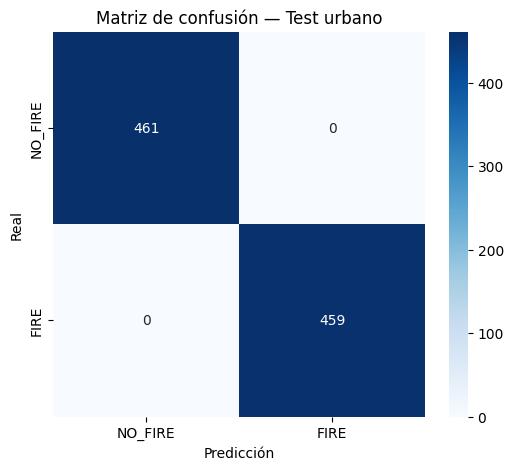

In [ ]:
# ============================================
# 19) MATRIZ DE CONFUSIÓN
# ============================================
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NO_FIRE", "FIRE"],
    yticklabels=["NO_FIRE", "FIRE"]
)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión — Test urbano")
plt.show()

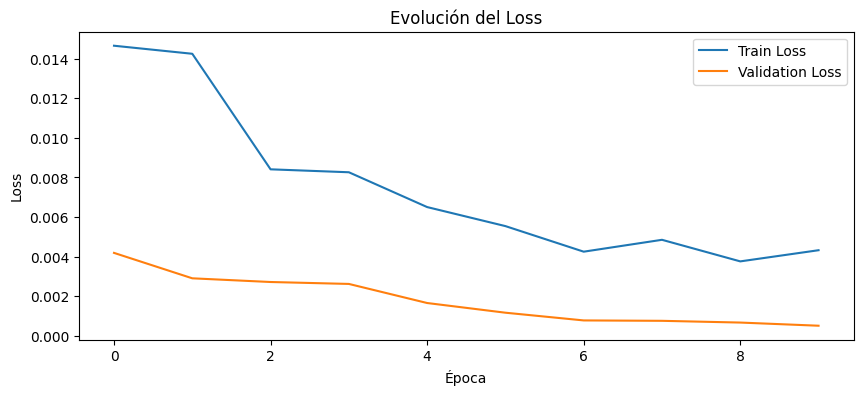

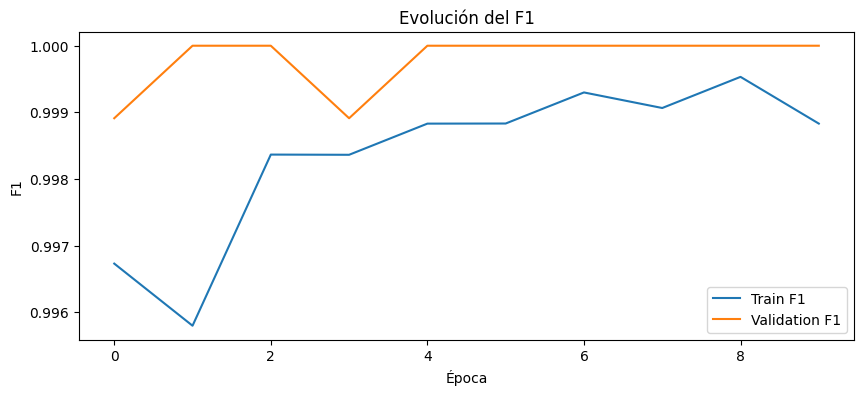

In [ ]:
# ============================================
# 20) CURVAS DE ENTRENAMIENTO
# ============================================
plt.figure(figsize=(10,4))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolución del Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history["train_f1"], label="Train F1")
plt.plot(history["val_f1"], label="Validation F1")
plt.xlabel("Época")
plt.ylabel("F1")
plt.title("Evolución del F1")
plt.legend()
plt.show()

## 9. Ver los falsos positivos

Esta sección es especialmente importante para demostrar que el modelo **no simplemente dice FIRE para cualquier imagen con colores naranja/rojo**.

Aquí se muestran imágenes reales de `NO_FIRE` que el modelo clasificó como `FIRE`, ordenadas por confianza.

In [ ]:
# ============================================
# 21) ANALIZAR FALSOS POSITIVOS
# ============================================
test_results = test_df.copy().reset_index(drop=True)
test_results["prob_fire"] = p_test
test_results["prediction"] = test_pred
test_results["correct"] = test_results["label"] == test_results["prediction"]

false_positives = test_results[
    (test_results["label"] == 0) &
    (test_results["prediction"] == 1)
].sort_values("prob_fire", ascending=False)

print("Falsos positivos encontrados:", len(false_positives))
display(false_positives[["path", "prob_fire"]].head(20))

Falsos positivos encontrados: 0


,path,prob_fire


In [ ]:
# ============================================
# 22) MOSTRAR FALSOS POSITIVOS
# ============================================
n_show = min(12, len(false_positives))

if n_show == 0:
    print("No hubo falsos positivos en este conjunto de prueba.")
else:
    cols = 4
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(16, 4 * rows))

    for i, (_, row) in enumerate(false_positives.head(n_show).iterrows()):
        img = Image.open(row["path"]).convert("RGB")

        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(img)
        ax.set_title(f"NO_FIRE → FIRE\nP={row['prob_fire']:.2%}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

No hubo falsos positivos en este conjunto de prueba.


## 10. Predicción de una imagen nueva

Puedes subir una imagen de una calle, vivienda, edificio, parque, vehículo, etc.

El modelo devuelve:
- probabilidad de FIRE;
- probabilidad de NO_FIRE;
- decisión;
- advertencia cuando la confianza es baja.

**Nota:** una CNN de clasificación no puede garantizar que exista un incendio real. Para un sistema operativo de seguridad sería necesario validarlo con imágenes de cámaras reales y, preferiblemente, incorporar detección/localización.

Saving imagen_2026-10-08_094615969.png to imagen_2026-10-08_094615969.png


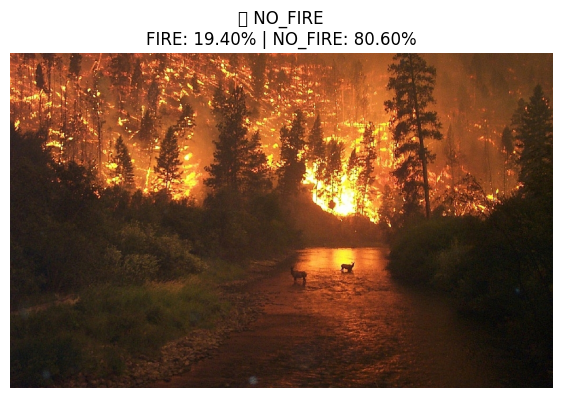

RESULTADO
Probabilidad FIRE:    19.40%
Probabilidad NO_FIRE: 80.60%
Umbral utilizado:     0.30
Decisión:              🏙️ NO_FIRE


In [ ]:
# ============================================
# 23) PREDICCIÓN DE IMAGEN NUEVA
# ============================================
from google.colab import files

def predict_image(path, threshold=best_threshold):
    model.eval()

    image = Image.open(path).convert("RGB")
    x = eval_tfms(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        prob_fire = torch.sigmoid(model(x)).item()

    prob_no_fire = 1.0 - prob_fire
    decision = "🔥 FIRE" if prob_fire >= threshold else "🏙️ NO_FIRE"

    plt.figure(figsize=(7,7))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{decision}\n"
        f"FIRE: {prob_fire:.2%} | NO_FIRE: {prob_no_fire:.2%}"
    )
    plt.show()

    print("===================================")
    print("RESULTADO")
    print("===================================")
    print(f"Probabilidad FIRE:    {prob_fire:.2%}")
    print(f"Probabilidad NO_FIRE: {prob_no_fire:.2%}")
    print(f"Umbral utilizado:     {threshold:.2f}")
    print(f"Decisión:              {decision}")

    if abs(prob_fire - threshold) < 0.10:
        print("\n⚠️ Advertencia: resultado cercano al umbral.")
        print("Conviene considerar la predicción como incierta.")

uploaded = files.upload()

for filename in uploaded:
    predict_image(filename)

## 11. Guardar el modelo

El archivo guardado contiene la red entrenada y el umbral seleccionado para la decisión.

In [ ]:
# ============================================
# 24) GUARDAR MODELO
# ============================================
MODEL_PATH = ROOT / "cnn_incendios_urbanos_resnet18.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "threshold": best_threshold,
    "img_size": IMG_SIZE,
    "architecture": "resnet18",
    "classes": ["NO_FIRE", "FIRE"]
}, MODEL_PATH)

print("Modelo guardado en:", MODEL_PATH)

Modelo guardado en: /content/fire_urban_project/cnn_incendios_urbanos_resnet18.pth


# 12. Conclusión para la exposición

### Problema inicial
El modelo anterior tendía a generar falsos positivos porque estaba entrenado con un conjunto pequeño y desbalanceado: había muchas más imágenes de fuego que de no fuego.

### Solución aplicada
1. Se incorpora un dataset específico para **entornos urbanos**.
2. Se utilizan imágenes de `Fire Urban` y `Normal Urban`.
3. Se balancean las clases.
4. Se aplican aumentaciones realistas para cámaras urbanas.
5. Se utiliza una CNN ResNet18 mediante transferencia de aprendizaje.
6. El umbral de decisión se calcula sobre validación.
7. Se analizan explícitamente los falsos positivos.
8. Se prueba el modelo con imágenes nuevas.

### Interpretación
El objetivo ya no es simplemente obtener una alta exactitud, sino disminuir el problema concreto de **detectar fuego donde no existe**, especialmente en escenas urbanas.

### Limitación
La clasificación `FIRE / NO_FIRE` indica si la imagen contiene señales compatibles con fuego; no localiza exactamente dónde está el fuego. Para eso, el siguiente paso sería un modelo de **detección de objetos o segmentación**.